# SPLC'23 — LLMs to generate meaningful feature model instances (versão atualizada)

Versão local e corrigida do notebook dos autores (`SPLC'23.ipynb`, mantido **intacto** como referência).
Roda no `.venv` do projeto (Python 3.12) — kernel **Python (splc23-llm)**. Setup: `./scripts/setup_env.sh`.

### O que mudou em relação ao original

| Célula original | Problema | Correção |
|---|---|---|
| todas | caminhos `./SPLC23-LLM-artefact/...` e `/content/` (Colab) | caminhos relativos à raiz via `replication.PATHS` |
| `!pip install flamapy ...` | Flamapy 2.x atual não lê 26/30 modelos | versões de 2023 fixadas (`requirements.txt`) |
| `fm_analysis.py` | `Glucose3FalseOptionalFeatures(self.fm)` — assinatura mudou | FM atribuído a `op.feature_model` |
| inferência | `breaked_strings[]` (erro de sintaxe); `text_file` fora de escopo; `.close` sem `()` | corrigido |
| inferência | `openai.Completion.create` / `openai.api_key` (SDK < 1.0, removido) | `OpenAI().completions.create`, chave lida do `.env` |
| inferência | sobrescrevia as respostas do Codex em `2.inference/1.API_call` | novas execuções vão para `2.inference/replication/<modelo>/` |
| experimento 2 | `DIRECTORY_UVL` indefinido; CSV em modo *append* duplica linhas a cada execução | `DIRECTORY_UVL_ORIGINAL`; CSV recriado |
| experimento 3 | `cohere`, `os`, `time`, `random` não importados; `co.embed([...])` (API v1) | `cohere.ClientV2().embed(model=..., input_type=...)` |
| experimento 3 | Cohere v2 (4096 dims) desativado | embeddings originais reaproveitados; v3.0 recalculado em `3.results/3.cohere_v3/` |
| `!cp`, `!sed`, `!mkdir` | dependentes de shell/Colab | `shutil` / `pathlib` |

As células que chamam APIs pagas estão protegidas por flags `RUN_*` (padrão `False`).

In [1]:
import os, sys, json, csv, time, random, shutil, warnings
from pathlib import Path

# raiz do repositório no sys.path (fm_characterization e replication)
ROOT = Path.cwd()
while not (ROOT / "replication").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from replication import PATHS, env, get_openai_client, get_cohere_client  # carrega o .env
warnings.filterwarnings("ignore")

FIG_DIR = PATHS["results"] / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Flags de execução (chamadas pagas / lentas) ----
RUN_FAMAXML_CONVERSION = False   # converte os 1215 modelos SPLOT (lento)
RUN_CODEX_STYLE_INFERENCE = False
RUN_REPLICATION_INFERENCE = False
RUN_COHERE_EMBEDDINGS = False

print("ROOT:", ROOT)
print("OPENAI_API_KEY definido:", bool(env("OPENAI_API_KEY")), "| COHERE_API_KEY definido:", bool(env("COHERE_API_KEY")))

ROOT: /home/leo/Documents/Mestrado/Mestrado1/EngSoftware/LLM_FM_INF2005
OPENAI_API_KEY definido: True | COHERE_API_KEY definido: False


# Passo 1 — Feature models: FamaXML → UVL

In [2]:
from flamapy.core.discover import DiscoverMetamodels

if RUN_FAMAXML_CONVERSION:
    dm = DiscoverMetamodels()
    PATHS["all_uvl"].mkdir(parents=True, exist_ok=True)
    ok, fail = 0, []
    for f in sorted(PATHS["famaxml"].glob("*.xml")):
        try:
            model = dm.use_transformation_t2m(str(f), "fm")
            dm.use_transformation_m2t(model, str(PATHS["all_uvl"] / f.with_suffix(".uvl").name))
            ok += 1
        except Exception as e:
            fail.append((f.name, type(e).__name__))
    print(f"convertidos: {ok}; falhas: {len(fail)}")

In [3]:
# Os 30 modelos selecionados manualmente pelos autores
selected = sorted(p.name for p in PATHS["selected_uvl"].glob("*.uvl"))
print(len(selected), selected)

30 ['DELL-LAPTOP-NOTEBOOK-FM.uvl', 'REAL-FM-1.uvl', 'REAL-FM-10.uvl', 'REAL-FM-11.uvl', 'REAL-FM-12.uvl', 'REAL-FM-13.uvl', 'REAL-FM-14.uvl', 'REAL-FM-15.uvl', 'REAL-FM-16.uvl', 'REAL-FM-17.uvl', 'REAL-FM-18.uvl', 'REAL-FM-19.uvl', 'REAL-FM-2.uvl', 'REAL-FM-20.uvl', 'REAL-FM-3.uvl', 'REAL-FM-4.uvl', 'REAL-FM-5.uvl', 'REAL-FM-6.uvl', 'REAL-FM-7.uvl', 'REAL-FM-8.uvl', 'REAL-FM-9.uvl', 'aircraft_fm.uvl', 'arcade_game_pl_fm.uvl', 'car_fm.uvl', 'cfdp_library_fm.uvl', 'connector_fm.uvl', 'fame_dbms_fm.uvl', 'movies_app_fm.uvl', 'smart_home_fm.uvl', 'stack_fm.uvl']


# Seleção de modelos — contagem de tokens

Tabs substituídos por 4 espaços (estilo de código), depois contagem com `tiktoken`
(`p50k_base` = Codex, `r50k_base` = GPT-3).

In [4]:
import tiktoken

shutil.copytree(PATHS["selected_uvl"], PATHS["selected_uvl_spaces"], dirs_exist_ok=True)
for f in PATHS["selected_uvl_spaces"].glob("*.uvl"):
    f.write_text(f.read_text().replace("\t", "    "))

davinci = tiktoken.get_encoding("p50k_base")  # Codex
gpt = tiktoken.get_encoding("r50k_base")      # GPT-3

token_counts = {}
for f in sorted(PATHS["selected_uvl_spaces"].glob("*.uvl")):
    s = f.read_text()
    token_counts[f.name] = (len(davinci.encode(s)), len(gpt.encode(s)))
    print(f"{f.name:32s} Codex: {token_counts[f.name][0]:5d}; GPT: {token_counts[f.name][1]:5d}")

DELL-LAPTOP-NOTEBOOK-FM.uvl      Codex:  1572; GPT:  2708
REAL-FM-1.uvl                    Codex:   714; GPT:  4100
REAL-FM-10.uvl                   Codex:   127; GPT:   558
REAL-FM-11.uvl                   Codex:   672; GPT:  3685
REAL-FM-12.uvl                   Codex:   137; GPT:   468
REAL-FM-13.uvl                   Codex:    98; GPT:   417
REAL-FM-14.uvl                   Codex:   157; GPT:   762
REAL-FM-15.uvl                   Codex:   196; GPT:   914
REAL-FM-16.uvl                   Codex:   209; GPT:  1041
REAL-FM-17.uvl                   Codex:   169; GPT:   711
REAL-FM-18.uvl                   Codex:   367; GPT:  1736
REAL-FM-19.uvl                   Codex:   409; GPT:  1888
REAL-FM-2.uvl                    Codex:   146; GPT:   703
REAL-FM-20.uvl                   Codex:   508; GPT:  4286
REAL-FM-3.uvl                    Codex:   318; GPT:  1838
REAL-FM-4.uvl                    Codex:  3208; GPT: 20601
REAL-FM-5.uvl                    Codex:   420; GPT:   784
REAL-FM-6.uvl 

# Inferência

### (a) Chamada original (estilo Codex: inserção na linha 10)

O Codex (`code-davinci-002`) foi desativado em março/2023; as 150 respostas originais estão em
`2.inference/1.API_call/` (38 delas com texto vazio). A função abaixo é a original, corrigida e
migrada para o SDK atual. Ela só funciona com modelos que ainda aceitam `suffix` na API legada de
completions. **Fidelidade:** o original enviava `str(lista_de_linhas)` como prompt (a *repr* da lista
Python, não o texto). Mantemos isso com `FAITHFUL_PROMPT=True`.

In [5]:
from replication.llm import codex_style_insertion

FAITHFUL_PROMPT = True  # replica o bug do original: prompt = str(list)
LINENO = 10             # linha de inserção

def generate_insertion_point(input_file, lineno=LINENO):
    with open(input_file) as text_file:
        prompt_lines = text_file.readlines()
    prompt_lines[lineno] = prompt_lines[lineno][:-1]
    prompt_lines[lineno + 1] = prompt_lines[lineno + 1] + "\n"
    return [prompt_lines[:lineno], prompt_lines[lineno:]]

def generate_uvl(client, model, input_file, output_dir, i):
    first, second = generate_insertion_point(input_file)
    prompt, suffix = (str(first), str(second)) if FAITHFUL_PROMPT else ("".join(first), "".join(second))
    response = codex_style_insertion(client, model, prompt, suffix)
    out = Path(output_dir) / f"{Path(input_file).name}_r_{i}"
    out.write_text(json.dumps(response, indent=2))
    time.sleep(random.randint(20, 40))  # como no original, para não estourar rate limit

if RUN_CODEX_STYLE_INFERENCE:
    client = get_openai_client()
    model = env("OPENAI_COMPLETIONS_MODEL", "gpt-3.5-turbo-instruct")
    out_dir = PATHS["replication"] / f"codex_style_{model}" / "1.API_call"
    out_dir.mkdir(parents=True, exist_ok=True)
    for f in sorted(PATHS["selected_uvl"].glob("*.uvl")):
        for x in range(1, 6):
            generate_uvl(client, model, f, out_dir, x)

### (b) Replicação: *instruction prompting* (texto da Seção 3 do artigo)

Prompt = contexto do artigo + instrução do artigo + modelo completo + formato de saída (acréscimo nosso).
Temperatura 0,7 e top-p 1 como no original. Funciona com OpenAI e com LLM local via Ollama
(`OPENAI_BASE_URL=http://localhost:11434/v1` no `.env`).

In [6]:
from replication.llm import instruction_prompt_variant

def slug(s):
    return "".join(c if c.isalnum() or c in "-._" else "_" for c in s)

if RUN_REPLICATION_INFERENCE:
    client = get_openai_client()
    model = env("OPENAI_MODEL", required=True)
    base = PATHS["replication"] / slug(model)
    (base / "1.API_call").mkdir(parents=True, exist_ok=True)
    (base / "2.new_models").mkdir(parents=True, exist_ok=True)
    for f in sorted(PATHS["selected_uvl"].glob("*.uvl")):
        for x in range(1, 6):
            out_uvl = base / "2.new_models" / f"{x}_{f.name}"
            if out_uvl.exists():
                continue  # retomável
            uvl, raw = instruction_prompt_variant(client, model, f.read_text())
            (base / "1.API_call" / f"{f.name}_r_{x}.json").write_text(json.dumps(raw, indent=2))
            out_uvl.write_text(uvl)
            print("ok", out_uvl.name)

### Montagem das variantes do Codex (resposta inserida na linha 10 do original)

In [7]:
def merge_codex_responses(api_dir, out_dir, lineno=LINENO):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    for f in sorted(PATHS["selected_uvl"].glob("*.uvl")):
        uvl_lines = f.read_text().splitlines(keepends=True)
        for x in range(1, 6):
            data = json.loads((Path(api_dir) / f"{f.name}_r_{x}").read_text())
            inserted = data["choices"][0]["text"]
            result = "".join(uvl_lines[:lineno]) + inserted + "".join(uvl_lines[lineno:])
            # o original usava print(...), que acrescenta um "\n" final
            (out_dir / f"{x}_{f.name}").write_text(result + "\n")

merge_codex_responses(PATHS["codex_api_calls"], PATHS["codex_new_models"])
print(len(list(PATHS["codex_new_models"].glob("*.uvl"))), "variantes do Codex montadas")

150 variantes do Codex montadas


# Experimento 1 — validade sintática
Artigo: 136 de 150 variantes válidas (≈ 90%).

In [8]:
def syntax_check(directory):
    dm = DiscoverMetamodels()
    bad = []
    files = sorted(p for p in Path(directory).glob("*.uvl"))
    for f in files:
        try:
            model = dm.use_transformation_t2m(str(f), "fm")
            # a relação "Other" indica estrutura inválida ou tipo de relação novo
            if "Other" in str(model):
                bad.append(f.name)
        except Exception:
            bad.append(f.name)
    return files, bad

files, bad = syntax_check(PATHS["codex_new_models"])
for b in bad:
    print("Instância mal gerada:", b)
print(f"\nInválidas: {len(bad)} de {len(files)} -> válidas: {len(files)-len(bad)} ({100*(len(files)-len(bad))/len(files):.1f}%)")

Instância mal gerada: 1_REAL-FM-12.uvl
Instância mal gerada: 1_REAL-FM-17.uvl
Instância mal gerada: 1_REAL-FM-2.uvl
Instância mal gerada: 1_aircraft_fm.uvl
Instância mal gerada: 2_REAL-FM-2.uvl
Instância mal gerada: 2_REAL-FM-6.uvl
Instância mal gerada: 2_aircraft_fm.uvl
Instância mal gerada: 3_REAL-FM-12.uvl
Instância mal gerada: 3_REAL-FM-2.uvl
Instância mal gerada: 3_aircraft_fm.uvl
Instância mal gerada: 4_REAL-FM-2.uvl
Instância mal gerada: 4_aircraft_fm.uvl
Instância mal gerada: 5_REAL-FM-2.uvl
Instância mal gerada: 5_aircraft_fm.uvl

Inválidas: 14 de 150 -> válidas: 136 (90.7%)


# Experimento 2 — métricas estruturais (fm_characterization)

In [9]:
import fm_characterization

METRICS_CSV_FILE = PATHS["results"] / "analysis.csv"

def model_metrics(model_file):
    model = DiscoverMetamodels().use_transformation_t2m(str(model_file), "fm")
    return fm_characterization.FMMetrics(model).get_metrics()

def run_metrics(generated_dir, csv_path):
    with open(csv_path, "w", newline="") as fh:   # recria (o original fazia append)
        w = csv.writer(fh)
        w.writerow(["modelName", "iteration", "property", "value"])
        for f in sorted(PATHS["selected_uvl"].glob("*.uvl")):
            candidates = [(0, f)] + [(i, Path(generated_dir) / f"{i}_{f.name}") for i in range(1, 6)]
            for it, path in candidates:
                if not path.is_file():
                    continue
                try:
                    for p in model_metrics(path):
                        v = len(p.value) if isinstance(p.value, list) else p.value
                        w.writerow([f.name, it, p.property.name, str(v)])
                except Exception:
                    print(f"O modelo {f.name} (iteração {it}) teve um problema; veja o experimento 1")

run_metrics(PATHS["codex_new_models"], METRICS_CSV_FILE)

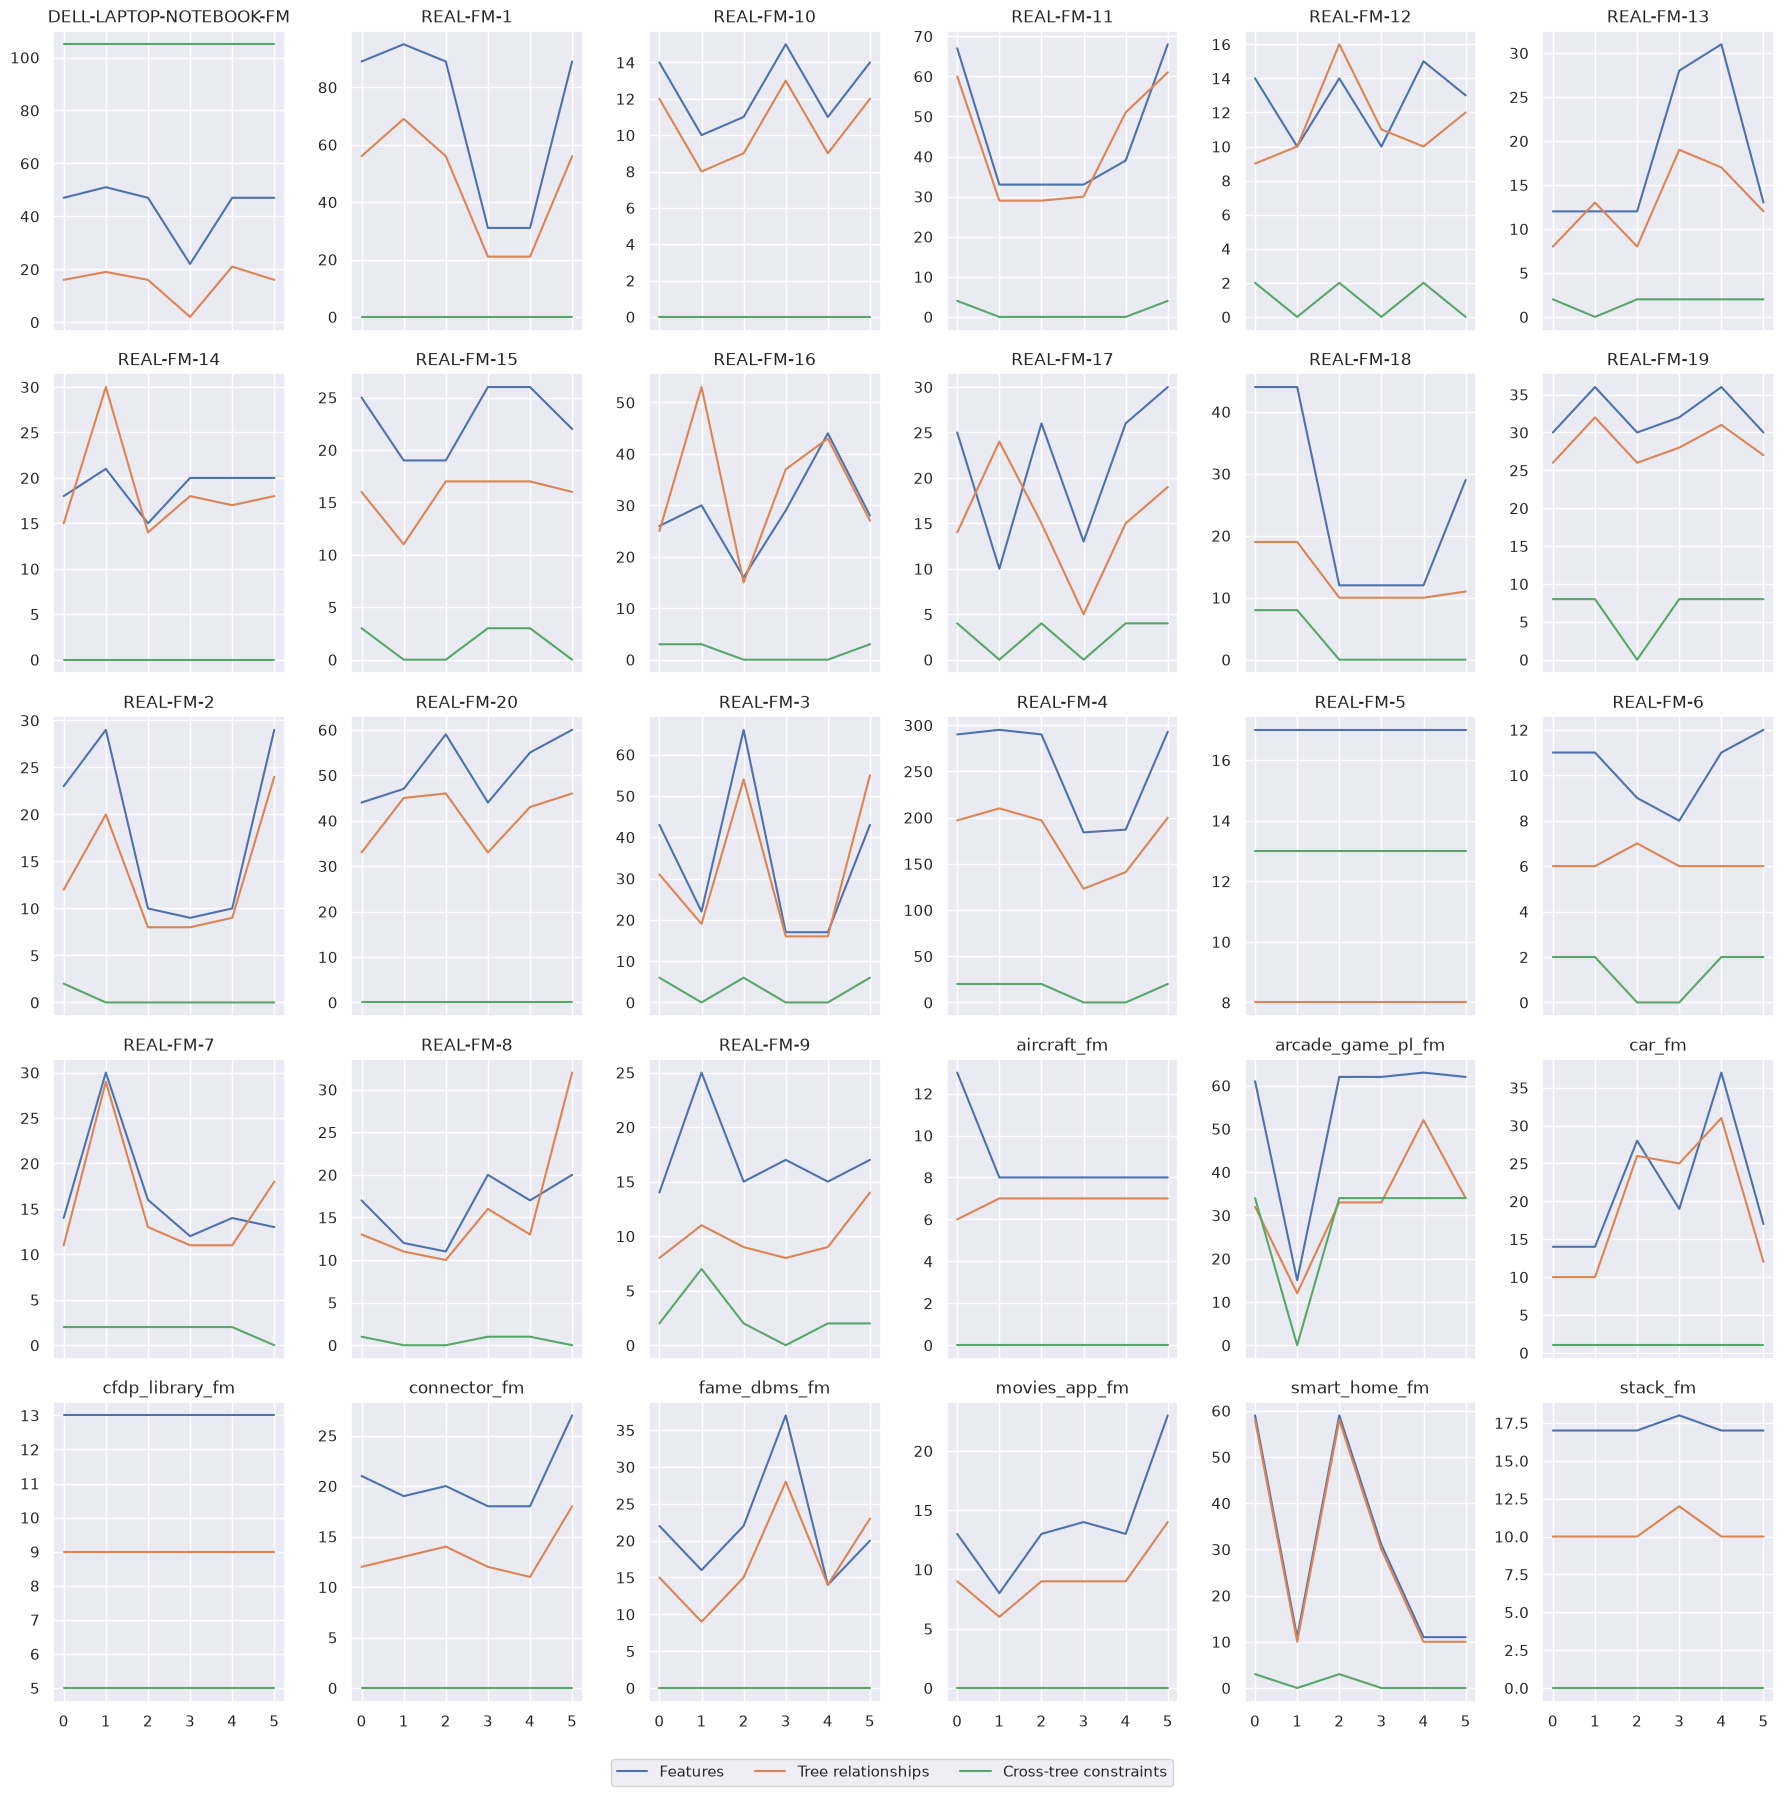

In [10]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

def plot_structure(csv_path, out_pdf):
    sns.set()
    fig, axes = plt.subplots(5, 6, figsize=(18, 18), sharex=True)
    df = pd.read_csv(csv_path, usecols=["modelName", "iteration", "property", "value"])
    df = df[df["property"].isin(["Features", "Cross-tree constraints", "Tree relationships"])].copy()
    df["value"] = df["value"].astype(int)
    uniques = df["modelName"].unique()
    for i, ax in enumerate(axes.flat):
        if i >= len(uniques):
            ax.axis("off"); continue
        d = df[df["modelName"] == uniques[i]]
        sns.lineplot(data=d, x="iteration", y="value", hue="property", ax=ax, legend=True, sort=True)
        ax.set_title(uniques[i].replace(".uvl", ""))
        ax.set(xlabel=None, ylabel=None)
        ax.set_xticks(range(0, 6), labels=range(0, 6))
        handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.05)
    fig.legend(handles, labels, loc="lower center", ncol=3)
    fig.savefig(out_pdf)
    plt.show()

plot_structure(METRICS_CSV_FILE, FIG_DIR / "semantics_structure.pdf")

# Experimento 3 — coerência de domínio (embeddings dos nomes de features)

1. Extrai a lista de nomes de features de cada modelo (original = iteração 0, variantes 1–5).
2. Embeddings da Cohere → similaridade de cosseno.

Os embeddings originais (Cohere v2, 4096 dims) estão em `3.results/2.cohere/` e **não podem ser
recalculados** (modelo desativado). Para a replicação recalculamos tudo com `embed-english-v3.0`
em `3.results/3.cohere_v3/`.

In [11]:
import numpy as np
from replication.embeddings import embed_text

def feature_string(model_file):
    model = DiscoverMetamodels().use_transformation_t2m(str(model_file), "fm")
    return " ".join(str(feat) for feat in model.get_features())

def compute_embeddings(generated_dir, out_root, co, model_name):
    (out_root / "strings").mkdir(parents=True, exist_ok=True)
    (out_root / "data").mkdir(parents=True, exist_ok=True)
    for f in sorted(PATHS["selected_uvl"].glob("*.uvl")):
        for it, path in [(0, f)] + [(i, Path(generated_dir) / f"{i}_{f.name}") for i in range(1, 6)]:
            if not path.is_file():
                continue
            npy = out_root / "data" / f"{it}_{f.name}_data.npy"
            if npy.exists():
                continue
            try:
                s = feature_string(path)
            except Exception:
                print("não parseia:", path.name); continue
            (out_root / "strings" / f"{it}_{f.name}_string").write_text(s + "\r\n")
            np.save(npy, embed_text(co, s, model=model_name))
            time.sleep(1)

if RUN_COHERE_EMBEDDINGS:
    compute_embeddings(PATHS["codex_new_models"], PATHS["cohere_v3"], get_cohere_client(),
                       env("COHERE_EMBED_MODEL", "embed-english-v3.0"))

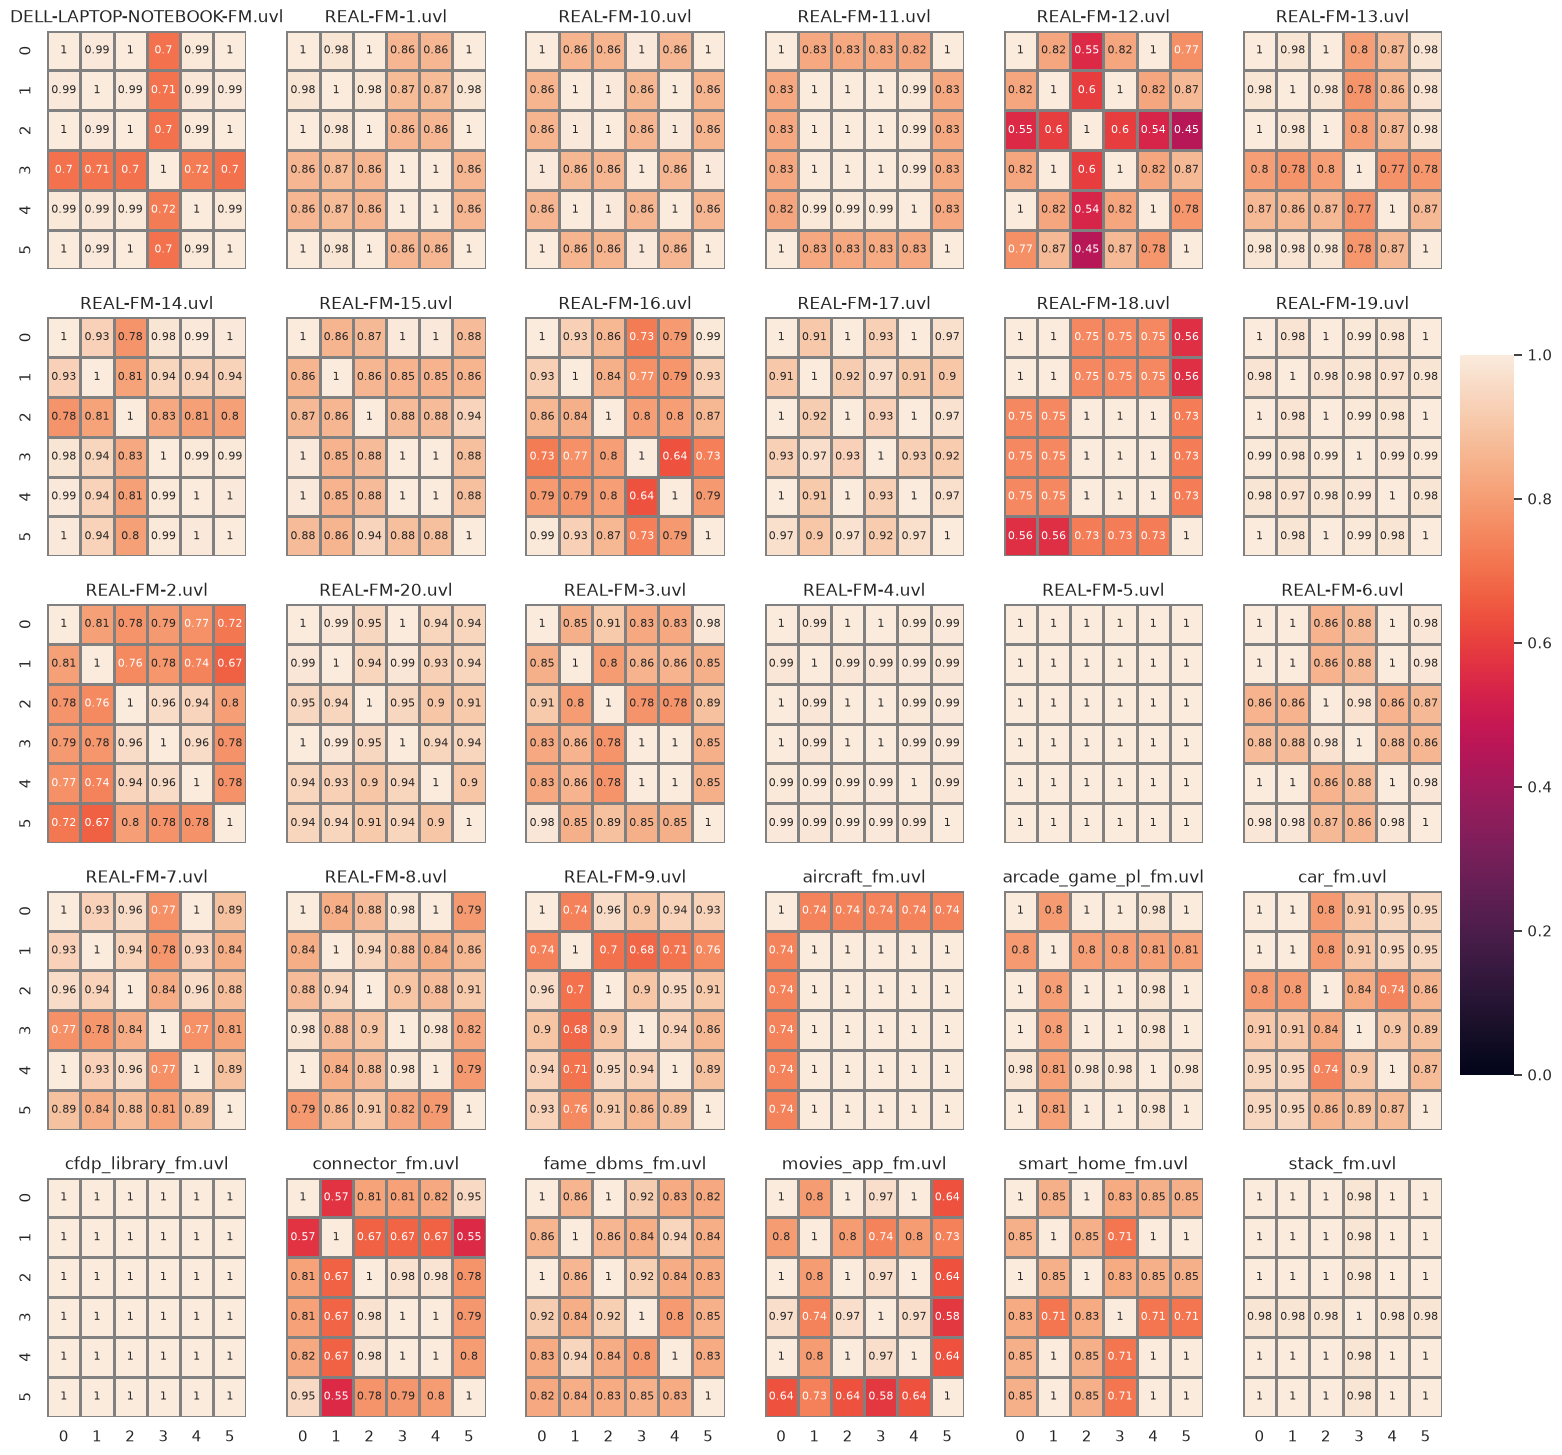

In [12]:
from sklearn.metrics.pairwise import cosine_similarity

def load_embeddings(emb_root):
    '''{modelo: {"0": emb, "1": emb, ...}} a partir de <emb_root>/data/*.npy'''
    out = {}
    for f in sorted(PATHS["selected_uvl"].glob("*.uvl"), key=lambda p: p.name):
        e = {}
        for it in range(0, 6):
            p = Path(emb_root) / "data" / f"{it}_{f.name}_data.npy"
            if p.exists():
                e[str(it)] = np.load(p)
        out[f.name] = e
    return out

def similarity_matrix(emb):
    keys = list(emb)
    return keys, [[cosine_similarity(emb[i], emb[j])[0][0] for i in keys] for j in keys]

def plot_domain(emb_root, out_pdf):
    all_emb = load_embeddings(emb_root)
    sns.set()
    fig, axes = plt.subplots(5, 6, figsize=(18, 18), sharex=True, sharey=True)
    cbar_ax = fig.add_axes([.91, .3, .03, .4])
    sims = {}
    for i, (ax, (name, emb)) in enumerate(zip(axes.flat, all_emb.items())):
        keys, m = similarity_matrix(emb)
        sims[name] = (keys, m)
        ax.set_title(name)
        sns.heatmap(m, vmin=0, vmax=1, ax=ax, cbar=i == 0, linewidths=1, linecolor="grey",
                    xticklabels=keys, yticklabels=keys, annot=True, annot_kws={"fontsize": 8},
                    cbar_ax=None if i else cbar_ax)
    fig.savefig(out_pdf)
    plt.show()
    return sims

sims_v2 = plot_domain(PATHS["cohere_v2"], FIG_DIR / "semantics_domain_v2.pdf")

In [13]:
# Similaridade original (0) vs cada variante — dados publicados (Cohere v2)
vals = [m[0][int(k)] for keys, m in sims_v2.values() for k in keys if k != "0"]
vals = np.array(vals)
print(f"n={len(vals)}  mediana={np.median(vals):.3f}  entre 0,5 e 0,8: {((vals>=0.5)&(vals<=0.8)).sum()}  "
      f"iguais a 1,0: {np.isclose(vals,1.0).sum()}  abaixo de 0,5: {(vals<0.5).sum()}")

n=150  mediana=0.943  entre 0,5 e 0,8: 27  iguais a 1,0: 29  abaixo de 0,5: 0


In [14]:
if PATHS["cohere_v3"].exists():
    sims_v3 = plot_domain(PATHS["cohere_v3"], FIG_DIR / "semantics_domain_v3.pdf")